# DiffEIMS: from an EI spectrum to candidate structures

**Spectrum + formula → peak tokens → encoder → conditioning vector y → diffusion over bonds, repeated 100 times → candidates ranked by how often they are sampled**

- **Encoder:** a MIST set transformer over the peaks. **Decoder:** a DiGress-style graph transformer that runs 500 reverse diffusion steps.
- **The formula is given, not inferred.** It fixes the heavy atoms, so the model only chooses the bonds.
- **Trained only on simulated spectra** (454k from NEIMS). Everything below uses real measured spectra from the Yee library.

In [1]:
# Reads saved results only. model_walkthrough_yee_full.ipynb regenerates the sampling files in CACHE_DIR.
import io
import os
import pickle as pkl
import re
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D

RDLogger.DisableLog('rdApp.*')

# Pickles written under numpy 2 reference numpy._core; alias it on numpy 1.x.
if not hasattr(np, '_core'):
    import numpy.core as _np_core
    sys.modules.setdefault('numpy._core', _np_core)
    for _sub in ('multiarray', 'numeric', '_multiarray_umath'):
        sys.modules.setdefault(f'numpy._core.{_sub}', getattr(_np_core, _sub))

RUN_TMS   = 'data/yee_new_0810/tms/outputs/2026-10-07/22-28-16-inference'
REF_CSV   = 'data/yee_new_0810/reference_inchi.csv'
YEE_DIR   = '../data/neims/yee/mist_inputs'
CACHE_DIR = 'data/yee_new_0810/tms/walkthrough_cache'

CATECHOL, HYDROQUINONE = 'LDY-20562', 'LDY-20550'
ISOMERS = {'ortho (catechol)': 'C[Si](C)(C)Oc1ccccc1O[Si](C)(C)C',
           'meta (resorcinol)': 'C[Si](C)(C)Oc1cccc(O[Si](C)(C)C)c1',
           'para (hydroquinone)': 'C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)cc1'}

# Same palette as test_set_overview.ipynb
C1, C2, C3, C4 = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
NEUTRAL, INK = '#b4b4b0', '#222222'
GRID_KW = dict(color='0.88', linewidth=0.6)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9.5, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.titleweight': 'bold', 'figure.dpi': 120, 'axes.axisbelow': True,
})


def load_cached(name):
    with open(os.path.join(CACHE_DIR, f'{name}.pkl'), 'rb') as f:
        return pkl.load(f)


def key_2d(inchi):
    "InChIKey of the 2D structure: stereo layers dropped, as generated molecules carry no stereo."
    return Chem.InchiToInchiKey(re.sub(r'/[btms][^/]*', '', inchi))


def wilson(k, n, z=1.96):
    "Wilson 95% interval for k successes in n trials."
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

## 1. The test case: two isomers, same atoms

The bis-TMS ethers of catechol and hydroquinone have the same formula, so the model gets identical atoms for both. Only the spectrum can tell them apart. The base peak differs: m/z 73 against m/z 239, [M-CH3]+.

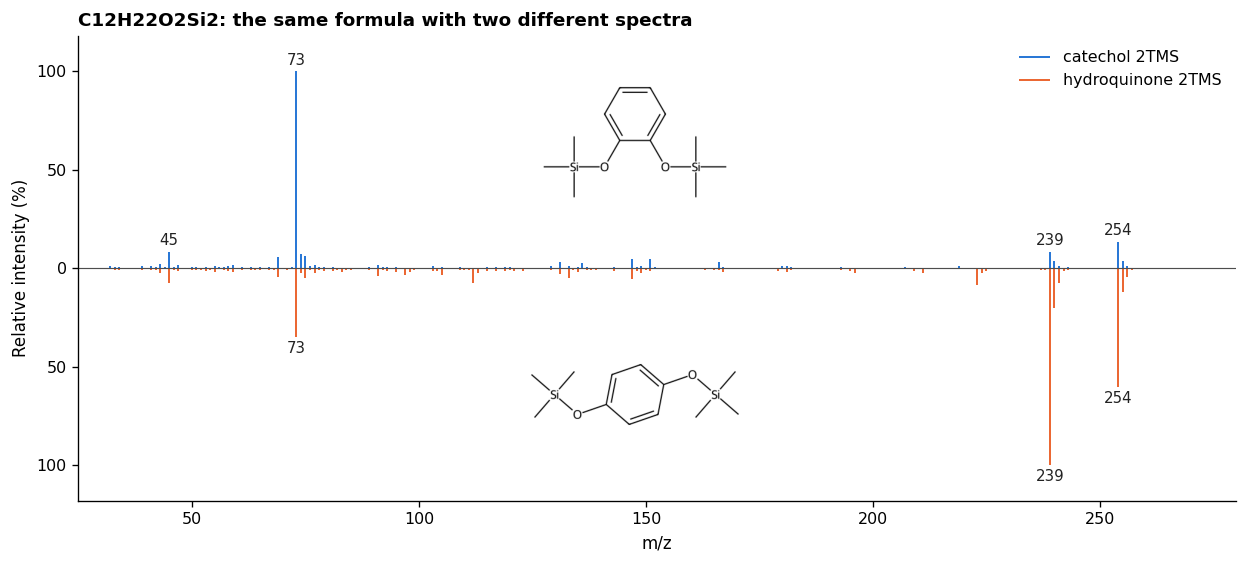

In [2]:
spec_df = pd.read_pickle(f'{YEE_DIR}/df_neims_yee_3_9_22.pkl').set_index('name')


def structure_image(smiles):
    "Black-and-white drawing at a fixed bond length, with the Si...Si axis level, so the two structures compare directly."
    mol = Chem.MolFromSmiles(smiles)
    AllChem.Compute2DCoords(mol)
    conf = mol.GetConformer()
    xy = conf.GetPositions()[:, :2]
    si = [a.GetIdx() for a in mol.GetAtoms() if a.GetSymbol() == 'Si']
    dx, dy = xy[si[1]] - xy[si[0]]
    c, s = dx / np.hypot(dx, dy), dy / np.hypot(dx, dy)
    for i, (x, y) in enumerate(xy):
        conf.SetAtomPosition(i, (c * x + s * y, c * y - s * x, 0.0))
    drawer = rdMolDraw2D.MolDraw2DCairo(620, 330)
    drawer.drawOptions().fixedBondLength = 34
    drawer.drawOptions().useBWAtomPalette()
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    return Image.open(io.BytesIO(drawer.GetDrawingText()))


fig, ax = plt.subplots(figsize=(10.5, 4.8))
for uid, sign, color, label, smiles in ((CATECHOL, 1, C1, 'catechol 2TMS', ISOMERS['ortho (catechol)']),
                                         (HYDROQUINONE, -1, C2, 'hydroquinone 2TMS', ISOMERS['para (hydroquinone)'])):
    s = np.asarray(spec_df.loc[uid, 'spec'], dtype=float)
    mz, inten = s[:, 0], s[:, 1] / s[:, 1].max() * 100
    ax.vlines(mz, 0, sign * inten, color=color, linewidth=1.2, label=label)
    labelled = []
    for i in np.argsort(-inten)[:5]:
        if all(abs(mz[i] - m) >= 4 for m in labelled):
            labelled.append(mz[i])
            ax.text(mz[i], sign * (inten[i] + 2), f'{mz[i]:.0f}', ha='center', va='bottom' if sign > 0 else 'top', fontsize=9, color=INK)
    # The structure in the empty middle of each half, as in the NIST viewer
    inset = ax.inset_axes([90, 14 if sign > 0 else -114, 115, 100], transform=ax.transData)
    inset.imshow(structure_image(smiles))
    inset.axis('off')
ax.axhline(0, color='0.3', linewidth=0.7)
ax.set(xlim=(25, 280), ylim=(-118, 118), xlabel='m/z', ylabel='Relative intensity (%)')
ax.set_yticks([-100, -50, 0, 50, 100], [100, 50, 0, 50, 100])
ax.set_title('C12H22O2Si2: the same formula with two different spectra')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 2. How a structure is generated

Sampling starts from random bonds drawn from the training statistics, with the atoms fixed. At each step the decoder, conditioned on y, predicts the clean bond types, and the next graph is sampled from that prediction. Aromatic bonds are dashed. Hydrogens are implicit.

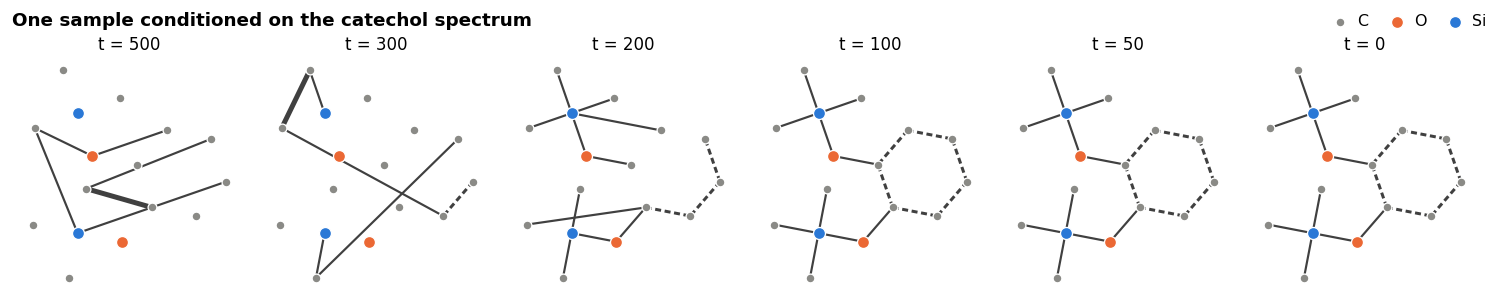

10 of 16 samples in this run gave catechol 2TMS.


In [3]:
traj = load_cached('trajectory_catechol')
chain, symbols = traj['chain'], traj['symbols']   # chain: step x sample x n x n, and chain[0] is t = 500
T = len(chain) - 1
ortho = Chem.CanonSmiles(ISOMERS['ortho (catechol)'])
pick = traj['smiles'].index(ortho)
BOND_TYPE = {1: Chem.BondType.SINGLE, 2: Chem.BondType.DOUBLE, 3: Chem.BondType.TRIPLE, 4: Chem.BondType.AROMATIC}
BOND_STYLE = {1: dict(linewidth=1.3, linestyle='-'), 2: dict(linewidth=3, linestyle='-'),
              3: dict(linewidth=4, linestyle='-'), 4: dict(linewidth=1.8, linestyle=(0, (2, 1.2)))}
ATOM_COLOR = {'C': '#8a8a86', 'O': C2, 'Si': C1}

# Draw every step on the layout of the final molecule, so that noise shows as wrong bonds
final = Chem.RWMol()
for sym in symbols:
    final.AddAtom(Chem.Atom(sym))
iu = np.triu_indices(len(symbols), 1)
for i, j in zip(*iu):
    if chain[-1, pick, i, j]:
        final.AddBond(int(i), int(j), BOND_TYPE[int(chain[-1, pick, i, j])])
final = final.GetMol()
Chem.SanitizeMol(final)
AllChem.Compute2DCoords(final)
pos = final.GetConformer().GetPositions()[:, :2]

show_t = [500, 300, 200, 100, 50, 0]
fig, axes = plt.subplots(1, len(show_t), figsize=(12.5, 2.5))
for ax, t in zip(axes, show_t):
    E = chain[T - t, pick]
    for i, j in zip(*iu):
        if E[i, j]:
            ax.plot(pos[[i, j], 0], pos[[i, j], 1], color='0.25', zorder=1, solid_capstyle='round', **BOND_STYLE[int(E[i, j])])
    for sym, color in ATOM_COLOR.items():
        idx = [i for i, a in enumerate(symbols) if a == sym]
        ax.scatter(pos[idx, 0], pos[idx, 1], s=52 if sym != 'C' else 28, color=color, edgecolor='white', linewidth=0.8, zorder=2, label=sym)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f't = {t}', fontsize=10, fontweight='normal', loc='center')
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc='upper right', ncol=3, handletextpad=0.1, columnspacing=0.8)
fig.suptitle('One sample conditioned on the catechol spectrum', x=0.01, ha='left', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()
print(f"{traj['smiles'].count(ortho)} of {len(traj['smiles'])} samples in this run gave catechol 2TMS.")

## 3. Does the spectrum drive the result?

These are new sampling runs with the same atoms and 48 samples per row, changing only y. The two lower rows replace the spectrum: one with the average y of all 730 spectra, the other with the y of an unrelated compound, heptadecanoic acid TMS.

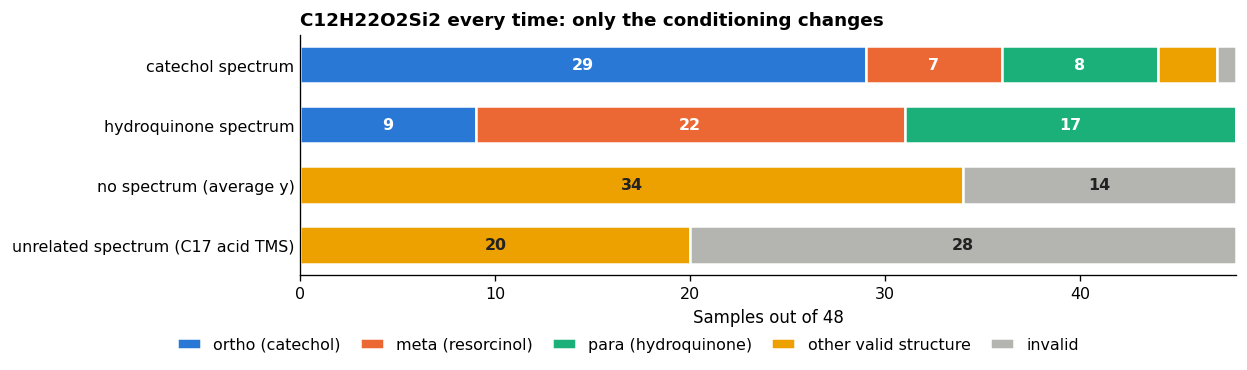

Valid samples with an aromatic ring:
  catechol spectrum: 47 of 47
  hydroquinone spectrum: 48 of 48
  no spectrum (average y): 0 of 34
  unrelated spectrum (C17 acid TMS): 0 of 20


In [4]:
conditions = {'catechol spectrum': load_cached('morph_0.00'),
              'hydroquinone spectrum': load_cached('morph_1.00'),
              'no spectrum (average y)': load_cached('control_mean_y'),
              'unrelated spectrum (C17 acid TMS)': load_cached('control_unrelated_y')}
ISO_CANON = {Chem.CanonSmiles(s): k for k, s in ISOMERS.items()}
CATS = list(ISOMERS) + ['other valid structure', 'invalid']
COLORS = [C1, C2, C3, C4, NEUTRAL]


def category(smiles):
    if smiles is None:
        return 'invalid'
    return ISO_CANON.get(smiles, 'other valid structure')


table = pd.DataFrame({k: Counter(map(category, v)) for k, v in conditions.items()}).T.reindex(columns=CATS).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(10.5, 3.3))
ypos, left = np.arange(len(table)), np.zeros(len(table))
for c, color in zip(CATS, COLORS):
    ax.barh(ypos, table[c], left=left, height=0.62, color=color, edgecolor='white', linewidth=1.5, label=c)
    for y_, l_, v in zip(ypos, left, table[c]):
        if v >= 4:
            ax.text(l_ + v / 2, y_, f'{v}', ha='center', va='center', fontsize=9.5, fontweight='bold',
                    color='white' if color in (C1, C2, C3) else INK)
    left += table[c].to_numpy()
ax.set_yticks(ypos, table.index)
ax.invert_yaxis()
ax.set(xlim=(0, 48), xlabel='Samples out of 48')
ax.set_title('C12H22O2Si2 every time: only the conditioning changes')
ax.tick_params(axis='y', length=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.35, -0.2), ncol=5, columnspacing=1.2, handlelength=1.5)
plt.tight_layout()
plt.show()

AROMATIC = Chem.MolFromSmarts('a')
print('Valid samples with an aromatic ring:')
for k, v in conditions.items():
    valid = [s for s in v if s]
    print(f'  {k}: {sum(Chem.MolFromSmiles(s).HasSubstructMatch(AROMATIC) for s in valid)} of {len(valid)}')

## 4. How often is it right, and can it tell?

This is the full run: 100 samples for each of the 730 library spectra, scored on the 135 with a NIST reference (2D match). The right panel asks whether the model's own output signals reliability: when many samples agree on one structure, is that structure correct?

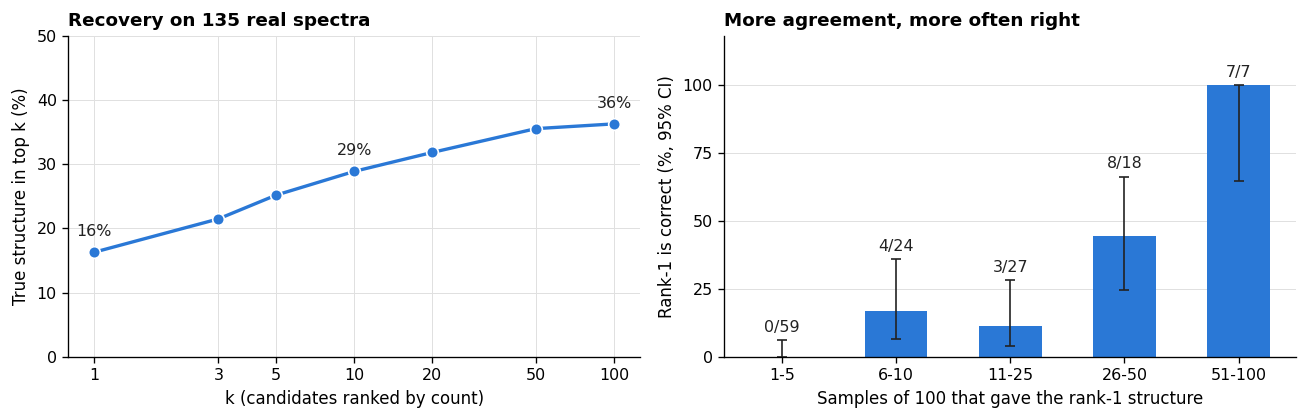

459 of 714 spectra with any valid candidate have a rank-1 count of 5 or less.


In [5]:
cand = pd.read_pickle(os.path.join(RUN_TMS, 'candidates_cache.pkl'))
cand['key_2d'] = cand['inchi'].map(key_2d)
cand = cand.sort_values('count', ascending=False, kind='stable')
refs = pd.read_csv(REF_CSV, dtype=str, keep_default_na=False).query("status == 'found'").set_index('uid')
ranked = {u: g['key_2d'].tolist() for u, g in cand.groupby('uid', sort=False)}
top_count = cand.groupby('uid', sort=False)['count'].first()

true_key = refs['inchi'].map(key_2d)
TOP_K = [1, 3, 5, 10, 20, 50, 100]
hits = [np.mean([true_key[u] in ranked.get(u, [])[:k] for u in refs.index]) * 100 for k in TOP_K]

BINS = [(1, 5), (6, 10), (11, 25), (26, 50), (51, 100)]
rel = []
for lo, hi in BINS:
    in_bin = [u for u in refs.index if lo <= top_count.get(u, 0) <= hi]
    k = sum(ranked[u][0] == true_key[u] for u in in_bin)
    rel.append((f'{lo}-{hi}', k, len(in_bin), *wilson(k, len(in_bin))))
rel = pd.DataFrame(rel, columns=['bin', 'k', 'n', 'lo', 'hi'])
rel['rate'] = rel['k'] / rel['n']

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(TOP_K, hits, color=C1, marker='o', markersize=7, markeredgecolor='white', linewidth=2)
for k, h in zip(TOP_K, hits):
    if k in (1, 10, 100):
        ax.text(k, h + 2.5, f'{h:.0f}%', ha='center', fontsize=9.5, color=INK)
ax.set_xscale('log')
ax.set_xticks(TOP_K, TOP_K)
ax.minorticks_off()
ax.set(xlabel='k (candidates ranked by count)', ylabel='True structure in top k (%)', ylim=(0, 50))
ax.set_title(f'Recovery on {len(refs)} real spectra')
ax.grid(**GRID_KW)

ax = axes[1]
xp = np.arange(len(rel))
ax.bar(xp, rel['rate'] * 100, width=0.55, color=C1)
ax.errorbar(xp, rel['rate'] * 100, yerr=[(rel['rate'] - rel['lo']) * 100, (rel['hi'] - rel['rate']) * 100], fmt='none', ecolor=INK, elinewidth=1, capsize=3)
for i, r in rel.iterrows():
    ax.text(i, r['hi'] * 100 + 3, f"{r['k']}/{r['n']}", ha='center', fontsize=9.5, color=INK)
ax.set_xticks(xp, rel['bin'])
ax.set_yticks([0, 25, 50, 75, 100])
ax.set(xlabel='Samples of 100 that gave the rank-1 structure', ylabel='Rank-1 is correct (%, 95% CI)', ylim=(0, 118))
ax.set_title('More agreement, more often right')
ax.grid(axis='y', **GRID_KW)
plt.tight_layout()
plt.show()
print(f'{(top_count <= 5).sum()} of {len(top_count)} spectra with any valid candidate have a rank-1 count of 5 or less.')

**Reading this.** The 7 of 7 is optimistic because it covers only spectra with a reference. Of the other named spectra above 50, reading library names against the candidates gives 3 right, 4 wrong and 1 undecided. Three of the wrong ones are ring-position errors, such as 3-methylcatechol given as 4-methylcatechol.

**Known limits**

- **Position on a ring:** ortho separates from the others, but meta and para do not. Retention index separates all three, and the model does not use it.
- **Aliphatic TMS esters:** rank-1 contains the group in only 15% of the 48 spectra that have it.
- **Hydrogen count:** half of rank-1 candidates in labelled spectra have the wrong H count, as hydrogens are not modelled.
- **Peak tokens:** at unit mass, the assigned subformulas are not real ions. m/z 73 is encoded as `C6H`, not C3H9Si+.